# Denoising Autoencoder (DAE) on MNIST

**Goal:** design, implement and evaluate a multi-layer Denoising Autoencoder that learns to recover clean handwritten digits from inputs corrupted with Gaussian noise (standard deviation 0.5).

| Step | What is done |
|---|---|
| 1. Data Preparation | Load MNIST, normalise to [0, 1], flatten to 784-d, build clean and noisy (σ = 0.5, clipped to [0, 1]) versions |
| 2. Architecture | 784 → 256 (ReLU) → 128 (ReLU, bottleneck) → 256 (ReLU) → 784 (Sigmoid) |
| 3. Training | Adam optimiser, MSE loss, 20 epochs, batch size 256 |
| 4. Results and Analysis | 3 × 5 grid: clean test image / noisy input / DAE reconstruction |

**Running on Kaggle:** click **Add Data** (right sidebar), search for an MNIST dataset (e.g. *MNIST in CSV* or *MNIST Dataset*) and add it. The loader in Section 1 finds it automatically under `/kaggle/input`. If no dataset is attached, it falls back to `keras.datasets.mnist`, which needs **Internet: On** in the notebook settings. No GPU is required.

## 0. Setup

In [1]:
import os
import gzip
import struct

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Assignment hyper-parameters
INPUT_DIM = 784        # 28 x 28 flattened
NOISE_STD = 0.5        # Gaussian noise standard deviation
EPOCHS = 20
BATCH_SIZE = 256
N_SHOW = 5             # number of test images to visualise

# Reproducibility
SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

KAGGLE_INPUT = "/kaggle/input"
OUTPUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

print("TensorFlow:", tf.__version__)
print("GPUs visible:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795456589.368150      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795456610.028234      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
GPUs visible: []


E0000 00:00:1795456613.892105      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 1. Data Preparation

**1.1 Load MNIST.** The loader looks for an attached Kaggle dataset in any of the common formats (IDX files, `mnist_train.csv` / `mnist_test.csv`, or `mnist.npz`) and otherwise falls back to `keras.datasets.mnist`.

In [2]:
def read_idx(path):
    """Read an IDX (ubyte) file, optionally gzip-compressed."""
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        ndim = magic & 0xFF
        dims = struct.unpack(">" + "I" * ndim, f.read(4 * ndim))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def find_files(root, predicate):
    hits = []
    for dirpath, _, files in os.walk(root):
        for name in files:
            if predicate(name.lower()):
                hits.append(os.path.join(dirpath, name))
    return sorted(hits)


def first(paths):
    return paths[0] if paths else None


def load_from_kaggle_input(root=KAGGLE_INPUT):
    """Try to load MNIST from a dataset attached to the notebook.
    Returns ((x_train, y_train), (x_test, y_test), source) or None."""
    if not os.path.isdir(root):
        return None

    # (a) IDX files, e.g. train-images.idx3-ubyte / t10k-images.idx3-ubyte
    paths = {
        "x_train": first(find_files(root, lambda n: n.startswith("train-images"))),
        "y_train": first(find_files(root, lambda n: n.startswith("train-labels"))),
        "x_test":  first(find_files(root, lambda n: n.startswith("t10k-images"))),
        "y_test":  first(find_files(root, lambda n: n.startswith("t10k-labels"))),
    }
    if all(paths.values()):
        data = {k: read_idx(p) for k, p in paths.items()}
        return ((data["x_train"], data["y_train"]),
                (data["x_test"], data["y_test"]), "Kaggle input (IDX files)")

    # (b) CSV files: first column = label, remaining 784 columns = pixels
    train_csv = first(find_files(root, lambda n: n.endswith(".csv") and "mnist" in n and "train" in n))
    test_csv = first(find_files(root, lambda n: n.endswith(".csv") and "mnist" in n and "test" in n))
    if train_csv and test_csv:
        tr = pd.read_csv(train_csv).to_numpy(dtype=np.uint8)
        te = pd.read_csv(test_csv).to_numpy(dtype=np.uint8)
        if tr.shape[1] == 785 and te.shape[1] == 785:
            return ((tr[:, 1:].reshape(-1, 28, 28), tr[:, 0]),
                    (te[:, 1:].reshape(-1, 28, 28), te[:, 0]), "Kaggle input (CSV files)")

    # (c) NumPy archive with keras-style keys
    npz = first(find_files(root, lambda n: n.endswith(".npz") and "mnist" in n))
    if npz:
        d = np.load(npz)
        return ((d["x_train"], d["y_train"]), (d["x_test"], d["y_test"]), "Kaggle input (NPZ file)")

    return None


def load_mnist():
    result = load_from_kaggle_input()
    if result is not None:
        return result
    print("No MNIST dataset found under /kaggle/input -> using keras.datasets.mnist (needs Internet: On).")
    try:
        (x_tr, y_tr), (x_te, y_te) = keras.datasets.mnist.load_data()
    except Exception as exc:
        raise RuntimeError(
            "Could not load MNIST. Either attach an MNIST dataset via 'Add Data' "
            "or enable Internet in the notebook settings."
        ) from exc
    return (x_tr, y_tr), (x_te, y_te), "keras.datasets.mnist"


(x_train_raw, y_train), (x_test_raw, y_test), source = load_mnist()
assert x_train_raw.shape[1:] == (28, 28) and x_test_raw.shape[1:] == (28, 28), "Unexpected image shape"

print("Source        :", source)
print("Train images  :", x_train_raw.shape, "| Test images:", x_test_raw.shape)

Source        : Kaggle input (CSV files)
Train images  : (60000, 28, 28) | Test images: (10000, 28, 28)


**1.2 Normalise to [0, 1] and 1.3 flatten each 28 × 28 image into a 784-dimensional vector.**

In [3]:
x_train_clean = (x_train_raw.astype("float32") / 255.0).reshape(-1, INPUT_DIM)
x_test_clean = (x_test_raw.astype("float32") / 255.0).reshape(-1, INPUT_DIM)

print("Clean train:", x_train_clean.shape, "| range: [%.1f, %.1f]" % (x_train_clean.min(), x_train_clean.max()))
print("Clean test :", x_test_clean.shape, "| range: [%.1f, %.1f]" % (x_test_clean.min(), x_test_clean.max()))

Clean train: (60000, 784) | range: [0.0, 1.0]
Clean test : (10000, 784) | range: [0.0, 1.0]


**1.4 Create the two versions of the data.**

- **Clean data:** the normalised MNIST vectors above (the *target* output).
- **Noisy data:** clean data + Gaussian noise (mean 0, standard deviation 0.5), then **clamped to [0, 1]** (the *network input*).

The noisy version is generated once and kept fixed. The same corruption is applied to the test set so the model can be evaluated and visualised on unseen noisy digits.

In [4]:
def add_gaussian_noise(x, std, generator):
    noise = generator.normal(loc=0.0, scale=std, size=x.shape).astype("float32")
    return np.clip(x + noise, 0.0, 1.0)   # keep pixel values within [0, 1]


x_train_noisy = add_gaussian_noise(x_train_clean, NOISE_STD, rng)
x_test_noisy = add_gaussian_noise(x_test_clean, NOISE_STD, rng)

# Sanity checks
assert x_train_noisy.shape == x_train_clean.shape
assert 0.0 <= x_train_noisy.min() and x_train_noisy.max() <= 1.0
assert 0.0 <= x_test_noisy.min() and x_test_noisy.max() <= 1.0

print("Noisy train:", x_train_noisy.shape, "| range: [%.2f, %.2f]" % (x_train_noisy.min(), x_train_noisy.max()))
print("Noisy test :", x_test_noisy.shape, "| range: [%.2f, %.2f]" % (x_test_noisy.min(), x_test_noisy.max()))

Noisy train: (60000, 784) | range: [0.00, 1.00]
Noisy test : (10000, 784) | range: [0.00, 1.00]


## 2. Autoencoder Architecture

Symmetric, multi-layer DAE:

| Part | Layer | Units | Activation |
|---|---|---|---|
| Input | Input | 784 | – |
| Encoder | Dense 1 | 256 | ReLU |
| Encoder | Dense 2 (bottleneck) | 128 | ReLU |
| Decoder | Dense 3 | 256 | ReLU |
| Decoder | Output | 784 | Sigmoid |

In [5]:
def build_dae(input_dim=INPUT_DIM):
    inputs = keras.Input(shape=(input_dim,), name="noisy_input")

    # Encoder
    x = layers.Dense(256, activation="relu", name="encoder_dense_1")(inputs)
    x = layers.Dense(128, activation="relu", name="bottleneck")(x)

    # Decoder
    x = layers.Dense(256, activation="relu", name="decoder_dense_3")(x)
    outputs = layers.Dense(input_dim, activation="sigmoid", name="output")(x)

    return keras.Model(inputs, outputs, name="denoising_autoencoder")


dae = build_dae()
dae.summary()

Model: "denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noisy_input (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,368 (1.79 MB)

 Trainable params: 468,368 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Training

- Optimiser: `adam`
- Loss: Mean Squared Error
- 20 epochs, batch size 256
- Input = noisy images, target = clean images

The noisy / clean test pair is passed as `validation_data` only to monitor generalisation per epoch; it does not influence the weights.

In [6]:
dae.compile(optimizer="adam", loss="mse")

history = dae.fit(
    x_train_noisy, x_train_clean,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test_noisy, x_test_clean),
    verbose=2,
)

Epoch 1/20
235/235 - 5s - 20ms/step - loss: 0.0558 - val_loss: 0.0328
Epoch 2/20
235/235 - 3s - 14ms/step - loss: 0.0282 - val_loss: 0.0246
Epoch 3/20
235/235 - 5s - 22ms/step - loss: 0.0230 - val_loss: 0.0213
Epoch 4/20
235/235 - 3s - 15ms/step - loss: 0.0207 - val_loss: 0.0196
Epoch 5/20
235/235 - 3s - 14ms/step - loss: 0.0193 - val_loss: 0.0185
Epoch 6/20
235/235 - 3s - 14ms/step - loss: 0.0182 - val_loss: 0.0178
Epoch 7/20
235/235 - 3s - 14ms/step - loss: 0.0175 - val_loss: 0.0173
Epoch 8/20
235/235 - 3s - 15ms/step - loss: 0.0169 - val_loss: 0.0167
Epoch 9/20
235/235 - 3s - 14ms/step - loss: 0.0164 - val_loss: 0.0164
Epoch 10/20
235/235 - 3s - 14ms/step - loss: 0.0160 - val_loss: 0.0161
Epoch 11/20
235/235 - 3s - 14ms/step - loss: 0.0156 - val_loss: 0.0158
Epoch 12/20
235/235 - 3s - 14ms/step - loss: 0.0153 - val_loss: 0.0156
Epoch 13/20
235/235 - 3s - 14ms/step - loss: 0.0151 - val_loss: 0.0154
Epoch 14/20
235/235 - 3s - 14ms/step - loss: 0.0149 - val_loss: 0.0151
Epoch 15/20
235

## 4. Results and Analysis

**4.1 Training curves**

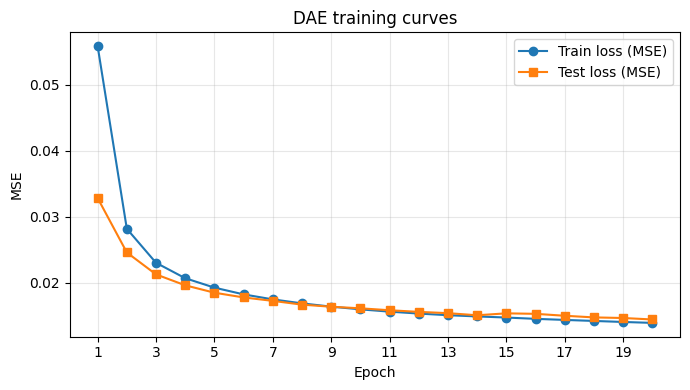

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history.history["loss"], marker="o", label="Train loss (MSE)")
plt.plot(range(1, EPOCHS + 1), history.history["val_loss"], marker="s", label="Test loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("DAE training curves")
plt.xticks(range(1, EPOCHS + 1, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**4.2 Visual results.** Three rows side by side for 5 different test images:

- **Row 1:** original clean test image
- **Row 2:** noisy input image
- **Row 3:** DAE reconstructed output

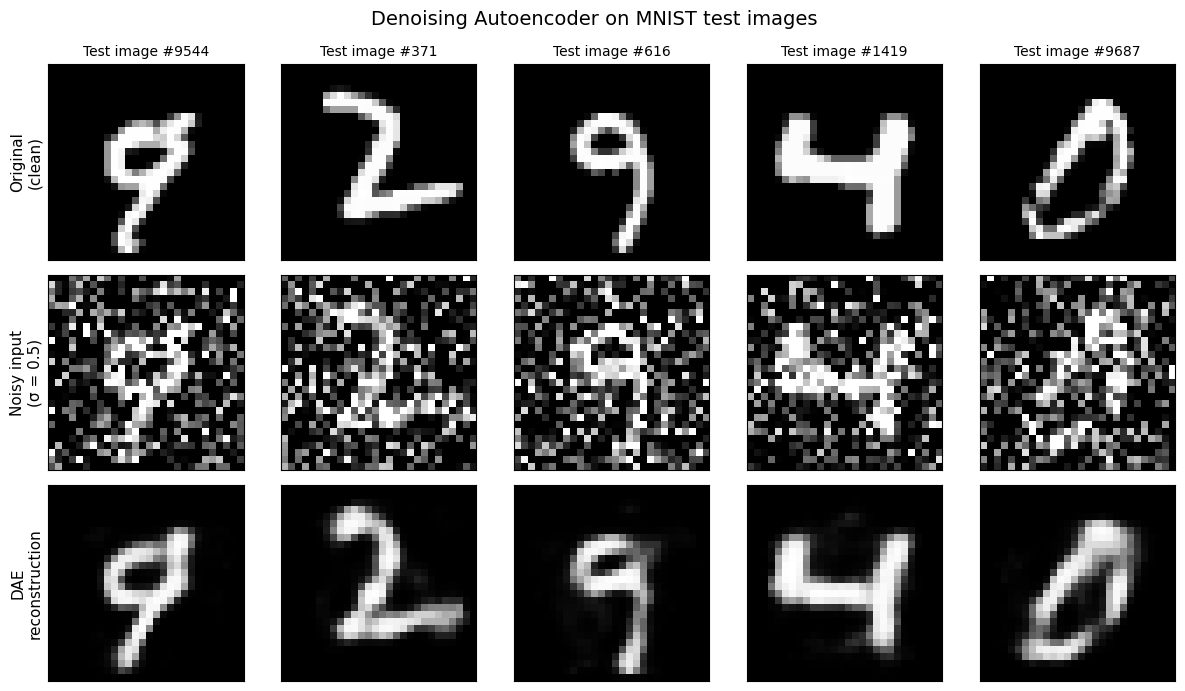

In [8]:
# Reconstruct the noisy test images
x_test_denoised = dae.predict(x_test_noisy, batch_size=BATCH_SIZE, verbose=0)

# Pick 5 different test images (fixed seed => reproducible)
idx = rng.choice(len(x_test_clean), size=N_SHOW, replace=False)

rows = [
    (x_test_clean[idx],    "Original\n(clean)"),
    (x_test_noisy[idx],    "Noisy input\n(\u03c3 = %.1f)" % NOISE_STD),
    (x_test_denoised[idx], "DAE\nreconstruction"),
]

fig, axes = plt.subplots(3, N_SHOW, figsize=(2.2 * N_SHOW + 1.2, 7))
for r, (images, row_label) in enumerate(rows):
    for c in range(N_SHOW):
        ax = axes[r, c]
        ax.imshow(images[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title("Test image #%d" % idx[c], fontsize=10)
        if c == 0:
            ax.set_ylabel(row_label, fontsize=11)

fig.suptitle("Denoising Autoencoder on MNIST test images", fontsize=14)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "dae_results.png"), dpi=150, bbox_inches="tight")
plt.show()

**4.3 Quantitative comparison on the full test set**

In [9]:
mse_noisy = float(np.mean((x_test_noisy - x_test_clean) ** 2))
mse_denoised = float(np.mean((x_test_denoised - x_test_clean) ** 2))
improvement = 100.0 * (1.0 - mse_denoised / mse_noisy)

print("Test MSE  noisy input    vs clean : %.5f" % mse_noisy)
print("Test MSE  DAE output     vs clean : %.5f" % mse_denoised)
print("Reduction in error                : %.1f %%" % improvement)

Test MSE  noisy input    vs clean : 0.11589
Test MSE  DAE output     vs clean : 0.01444
Reduction in error                : 87.5 %


**4.4 Discussion**

- **What the figure shows.** With σ = 0.5 the noisy inputs (row 2) are heavily corrupted: the background is speckled and parts of each stroke are hidden. The reconstructions (row 3) should show a clean background and continuous strokes that resemble the originals in row 1.
- **Why it works.** The network is trained on noisy → clean pairs, so it cannot simply copy its input. The 128-unit bottleneck forces a compact representation that keeps the structure shared across digits (strokes, loops, overall shape), while random noise has no such structure and is discarded.
- **Quantitative check.** The error of the noisy input against the clean image (4.3) is the error you would have with no denoising at all. The DAE output should have a clearly lower MSE; the training and test curves in 4.1 should stay close, which indicates the model is not simply memorising the training set.
- **Limitations.** MSE favours the average of plausible outputs, so reconstructions tend to be slightly smoother or blurrier than the originals, and very ambiguous digits can be restored with a malformed shape. Fully-connected layers also ignore the 2-D layout of the image; a convolutional DAE would likely preserve fine detail better.